# Lab 4: Working with Real Data

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py
from pathlib import Path
import pandas as pd

### Getting data and HD5
In general exchanging raw data is a pain. Writing data in text files is error prone, inaccurate, and wastes space, but raw binary files have all sorts of subtleties too (including the internal byte order of your processor). To try and sidestep a whole set of nasty issues, we are going to use HDF5 (originally developed by the National Center for Supercomputing Applications for data exchange) to allow everyone to import the data. HDF5 has become a prefered way for projects to save and exchange data.

In [2]:
hf = h5py.File('gammaray_lab4.h5', 'r')

In [3]:
hf.keys()

<KeysViewHDF5 ['data']>

In [4]:
data = np.array(hf.get('data'))

In [5]:
np.shape(data)
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

In [6]:
hf.close()

# Problem
In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

### 1. Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf()

In [7]:
df = pd.DataFrame(data, index = ['Time[gps sec]','Solar Phase[deg]', 'Earth Long.[deg]', 'Particle Counts' ]).transpose()

In [8]:
t = df.iloc[:,0].to_numpy()
phase = df.iloc[:,1].to_numpy()
long = df.iloc[:,2].to_numpy()
counts = df.iloc[:,3].to_numpy()

In [9]:
t_folded = t % (60*90)

In [10]:
df.insert(0, 'Folded Time', t_folded)

In [11]:
df

,Folded Time,Time[gps sec],Solar Phase[deg],Earth Long.[deg],Particle Counts
0,16.0,940680016.0,315.000000,45.000000,10.0
1,16.1,940680016.1,315.007112,45.006667,8.0
2,16.2,940680016.2,315.014225,45.013333,7.0
3,16.3,940680016.3,315.021337,45.020000,11.0
4,16.4,940680016.4,315.028449,45.026667,8.0
...,...,...,...,...,...
25919996,15.6,943272015.6,345.304884,44.973333,5.0
25919997,15.7,943272015.7,345.311996,44.980000,9.0
25919998,15.8,943272015.8,345.319109,44.986667,8.0
25919999,15.9,943272015.9,345.326221,44.993333,11.0


In [12]:
orbits = (t.max() - t.min())/60 / 90
print(f'The satellite makes {orbits} orbits over the observation timeframe')

The satellite makes 480.0 orbits over the observation timeframe


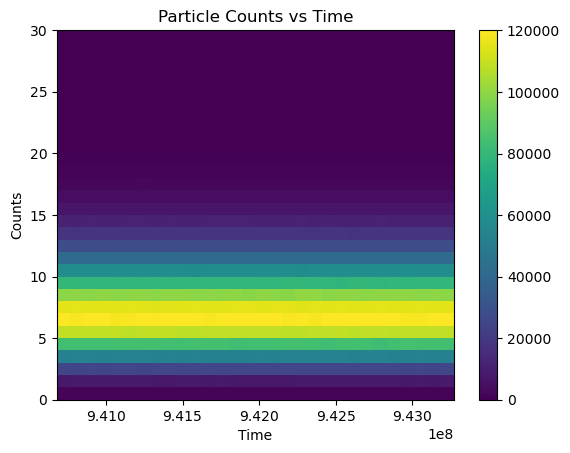

In [13]:
fig, ax = plt.subplots()

im = ax.hist2d(t, counts, bins = 30, cmap = 'viridis');

cbar = fig.colorbar(im[3], ax = ax)
ax.set_xlabel('Time')
ax.set_ylabel('Counts')
ax.set_title('Particle Counts vs Time')
plt.show()

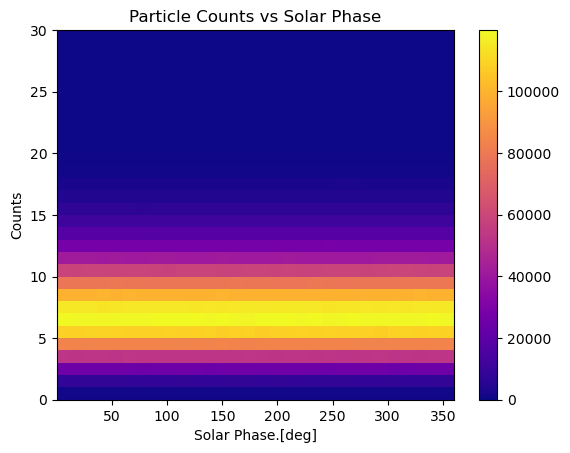

In [14]:
fig, ax = plt.subplots()

im = ax.hist2d(phase, counts, bins = 30, cmap = 'plasma');

cbar = fig.colorbar(im[3], ax = ax)
ax.set_xlabel('Solar Phase.[deg]')
ax.set_ylabel('Counts')
ax.set_title('Particle Counts vs Solar Phase')
plt.show()

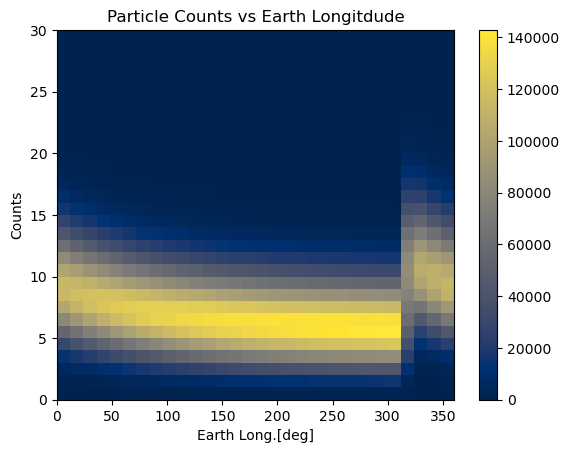

In [15]:
fig, ax = plt.subplots()

im = ax.hist2d(long, counts, bins = 30, cmap = 'cividis');

cbar = fig.colorbar(im[3], ax = ax)
ax.set_xlabel('Earth Long.[deg]')
ax.set_ylabel('Counts')
ax.set_title('Particle Counts vs Earth Longitdude')
plt.show()

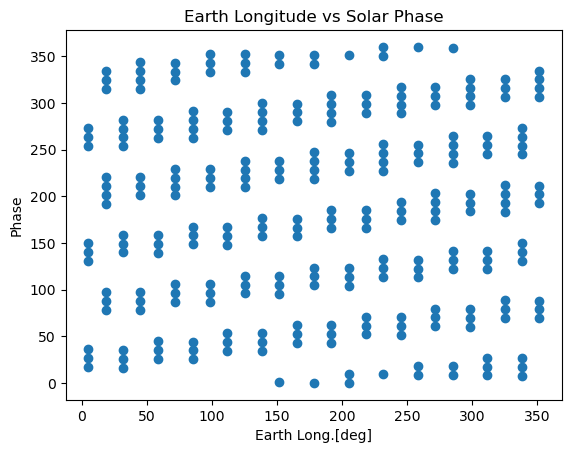

In [16]:
fig, ax = plt.subplots()

ax.scatter(long[::100000], phase[::100000])

# cbar = fig.colorbar(im[3], ax = ax)
ax.set_xlabel('Earth Long.[deg]')
ax.set_ylabel('Phase')
ax.set_title('Earth Longitude vs Solar Phase')
plt.show()

**Description of plots**
From the 2d histogram of time vs particle counts, it appears that there is a relatively constant background coming from the cosmic rays that peaks around 6 counts per observation, this consistency is also seen in the plot of solar phase vs particle counts. 

However, we see a break in the background consistency when looking at the plot of Earth Longitude vs Particle Counts, where the background suddenly seems to rise at a longitude of about 320 deg, then slowly ramps down back to the baseline. 

Based on the graphs, there does not appear to be significant signal contamination, there are no regions of high count that significantly differ from the background noise. 

To build a background pdf, we can make a histogram of the counts, both the total counts, and the counts in a given time interval, and test different overplotted distributions to see which fits best(likely a Poisson distribution).


### 2. The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

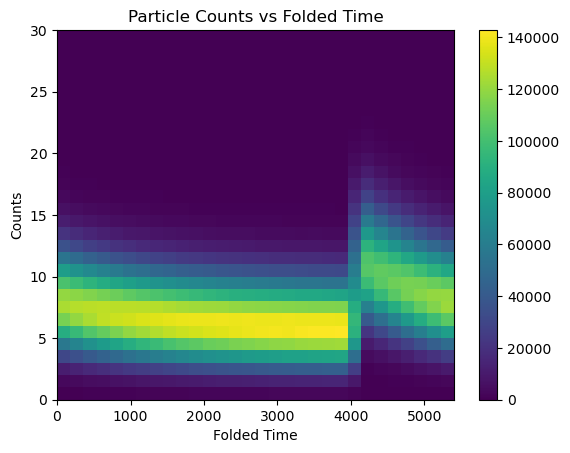

In [17]:
fig, ax = plt.subplots()

im_folded = ax.hist2d(t_folded, counts, bins = (30,30), cmap = 'viridis');

cbar = fig.colorbar(im_folded[3], ax = ax)
ax.set_xlabel('Folded Time')
ax.set_ylabel('Counts')
ax.set_title('Particle Counts vs Folded Time')
plt.show()

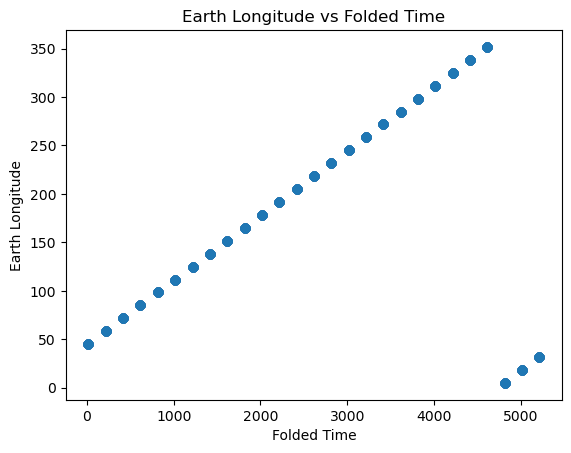

In [18]:
fig, ax = plt.subplots()

ax.scatter(t_folded[::10000], long[::10000])

# cbar = fig.colorbar(im[3], ax = ax)
ax.set_xlabel('Folded Time')
ax.set_ylabel('Earth Longitude')
ax.set_title('Earth Longitude vs Folded Time')
plt.show()

From our original analysis, the only plot which revealed a deviation in the background was the Particle Counts vs Earth longitude. This seemed strange since it implies that the background is not actually constant over time, since the Earth longitude is changing in time with the orbit, but the Particle Counts vs Time graph didn't include the deivation. 

This discrepancy is explained in that the total time of observation contains 480 orbits of the satellite, which when plotted all together hide the deviation from the mean background. But when you fold the time based on the orbital period of 90 minutes, you reveal the inconsistency in the background that mirrors the Earth longitude plot. 

So the true background behavior is that of the Counts vs Longitude plot, the background is relatively constant peaking around 6 counts for a majority of the orbit, then sharply jumps to over 10 counts per observation at a longitude of about 320, then steadily decays back down to the 6 count per observation average.

### Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

**Average PDF**

Text(0, 0.5, 'Prob Density')

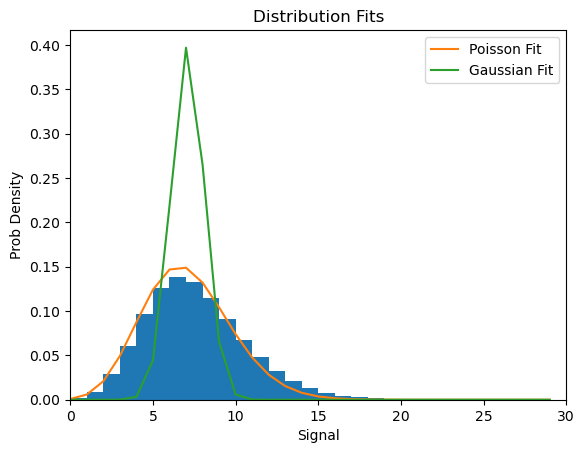

In [19]:
# histogram of total counts
avg_count = np.mean(counts)

x_range = np.arange(0,30,1)
fish_tot = stats.poisson.pmf(x_range, avg_count)
norm_tot = stats.norm.pdf(x_range, avg_count)
fig, ax = plt.subplots()

ax.hist(counts, bins = 30, density = True)
ax.plot(x_range, fish_tot, label = 'Poisson Fit')
ax.set_xlim(0,30)
# ax.set_ylim(0,0.15)
ax.plot(x_range, norm_tot, label = 'Gaussian Fit')
ax.legend(loc = 0)
ax.set_title('Distribution Fits')
ax.set_xlabel('Signal')
ax.set_ylabel('Prob Density')

Text(0, 0.5, 'log Prob Density')

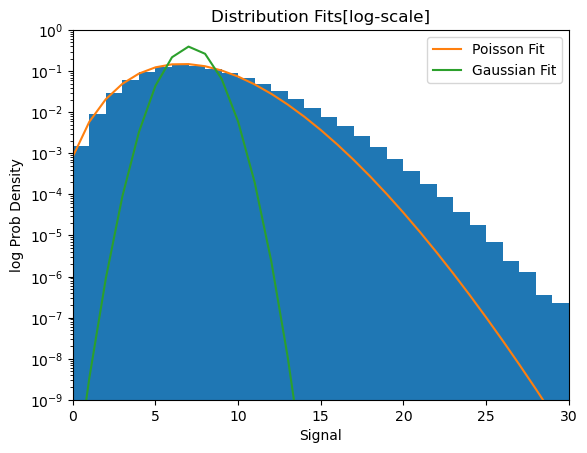

In [20]:
fig, ax = plt.subplots()

ax.hist(counts, bins = 30, density = True)
ax.plot(x_range, fish_tot, label = 'Poisson Fit')
ax.plot(x_range, norm_tot, label = 'Gaussian Fit')
ax.set_xlim(0,30)
ax.set_ylim(1e-9,1)
ax.set_yscale('log')
ax.legend(loc = 0)

ax.set_title('Distribution Fits[log-scale]')
ax.set_xlabel('Signal')
ax.set_ylabel('log Prob Density')

The above plots show that for a time independent model of the average background, a Poisson distribution fits fairly well which is typical for discrete signals that we've seen so far, whereas a normal distribution does not match the background well at all.

**Time Dependent PDF**

In [21]:
def counts_in_range(dataframe, time, delta_t = 1):
    """
    Gathers the signal measurments stored in dataframe within range delta_t of set time of the orbit of the satellite
    """
    x = dataframe[(dataframe['Folded Time'] < (time + delta_t)) & (dataframe['Folded Time'] >= (time))]['Particle Counts']
    counts = x.to_numpy()

    return counts

In [22]:
c_t1 = counts_in_range(df, 1000, 1000)
c_t2 = counts_in_range(df, 2000, 1000)
c_t3 = counts_in_range(df, 3000, 1000)
c_t4 = counts_in_range(df, 4000, 1000)

avgs = []
for i in c_t1, c_t2, c_t3, c_t4:
    avgs.append(np.mean(i))

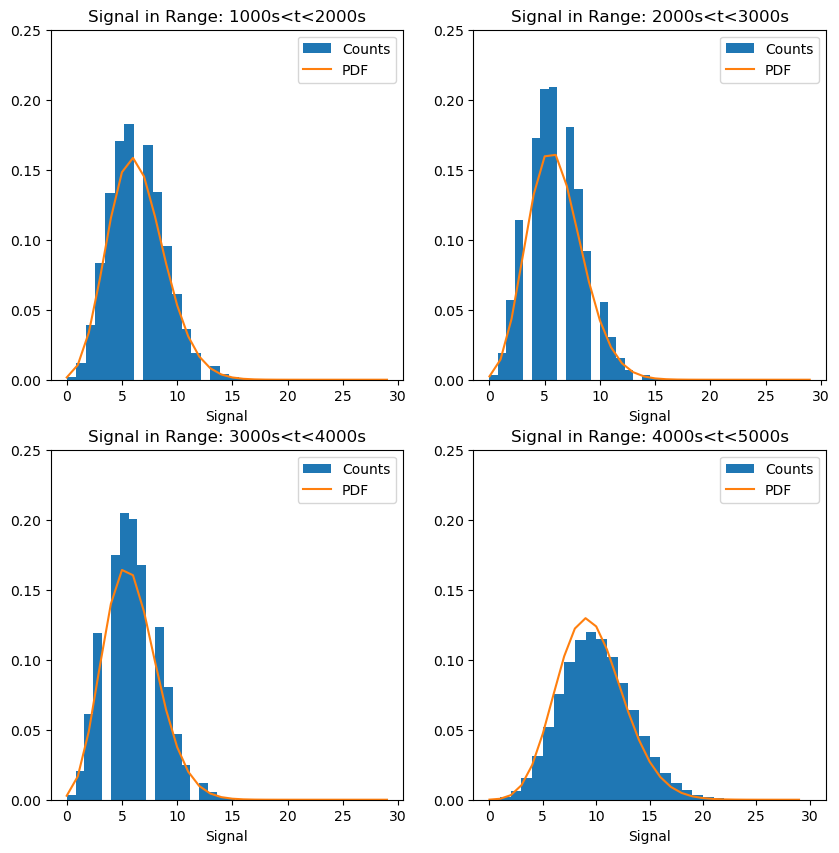

In [23]:
fig, ax = plt.subplot_mosaic(
    """
    AB
    CD
    """,
    figsize = (10,10)
)

ax['A'].hist(c_t1, bins = 30, density = True, label = 'Counts')
ax['A'].plot(x_range, stats.poisson.pmf(x_range, avgs[0]), label = 'PDF')
ax['A'].set_ylim(0,0.25)
ax['A'].set_title('Signal in Range: 1000s<t<2000s')
ax['A'].set_xlabel('Signal')
ax['A'].legend(loc = 0)

ax['B'].hist(c_t2, bins = 30, density = True, label = 'Counts')
ax['B'].plot(x_range, stats.poisson.pmf(x_range, avgs[1]), label = 'PDF')
ax['B'].set_ylim(0,0.25)
ax['B'].set_title('Signal in Range: 2000s<t<3000s')
ax['B'].set_xlabel('Signal')
ax['B'].legend(loc = 0)

ax['C'].hist(c_t3, bins = 30, density = True, label = 'Counts')
ax['C'].plot(x_range, stats.poisson.pmf(x_range, avgs[2]), label = 'PDF')
ax['C'].set_ylim(0,0.25)
ax['C'].set_title('Signal in Range: 3000s<t<4000s')
ax['C'].set_xlabel('Signal')
ax['C'].legend(loc = 0)

ax['D'].hist(c_t4, bins = 30, density = True, label = 'Counts')
ax['D'].plot(x_range, stats.poisson.pmf(x_range, avgs[3]), label = 'PDF')
ax['D'].set_ylim(0,0.25)
ax['D'].set_title('Signal in Range: 4000s<t<5000s')
ax['D'].set_xlabel('Signal')
ax['D'].legend(loc = 0)

### 4. Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

In [24]:
t_range = np.arange(1000, np.max(t_folded), 50)

In [25]:
def find_sigma(time, dt = 0.1):
    counts = counts_in_range(df, time, delta_t = dt)
    mean = np.mean(counts)
    prob5s = stats.norm.sf(5)
    thresh = stats.poisson.isf(prob5s, mu = mean)

    return thresh

In [26]:
th =[]
for i in range(0, len(t_range)):
    th.append(find_sigma(i))

Text(0.5, 0, 'Time')

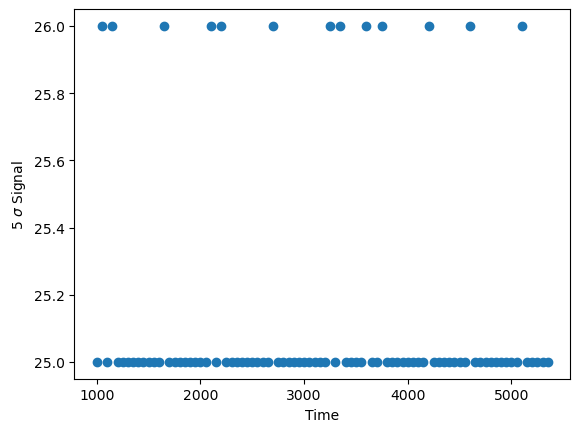

In [27]:
fig, ax = plt.subplots()

ax.scatter(t_range, th)
ax.set_ylabel(r'5 $\sigma$ Signal')
ax.set_xlabel('Time')

This plot does not show any obvious trend in the 5 sigma value with time. This is likely because for the 1ms range, not enough counts are present to properly fill in a Poisson background distribution, resulting in flat values.

In [28]:
th = []
t_range = np.arange(0,5000, 100)
for i in range(0, len(t_range)):
    th.append(find_sigma(t_range[i], 200))

Text(0.5, 1.0, '5$\\sigma$ Value vs Time')

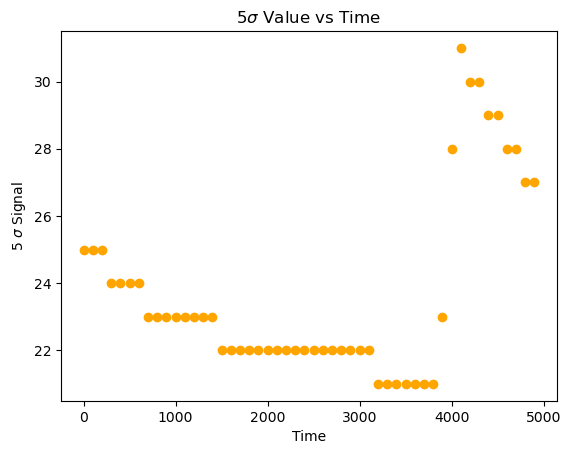

In [29]:
fig, ax = plt.subplots()

ax.scatter(t_range, th, color = 'orange')
ax.set_ylabel(r'5 $\sigma$ Signal')
ax.set_xlabel('Time')
ax.set_title(r'5$\sigma$ Value vs Time')

By broadening the time interval, a more meaningful trend of the 5 sigma value over time appears. We see it is in agreement with the histrogram of signal vs folded time, and signal vs Earth longitude, in that as the background starts higher at t=0, so is the 5 sigma val, it then decreases and becomes more constant as the background evens out, then jumps sharply aroound t=4000 when the background suddenly increases.

### 5. While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

Since the background varies with folded time and therefore Earth longitude, it seems that the spike in background/cosmis rays occurs consistently over a particular region of Earth. The longitude of the increase is about 320 degrees E, or 40 degrees W, which is roughly over the Atlantic Ocean and through part of South America. This region corresponds to the **South Atlantic Anomaly**, which is a region of the globe centered around Brazil/the nearby Atlantic Ocean, where the Earth's magnetic field is the weakest. Since charged particles and cosmic rays are repelled by the magnetic field, this region of weak field allows for an increased count of energetic particles to penetrate closer to the planet. As the sattelite moves through this region, its detector picks up on the increase in the particle flux. 